<a href="https://colab.research.google.com/github/kpmunoz09/DeepLearning/blob/main/explicacion_reconstruccion_de_imagenes_basico_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from keras.datasets import mnist
from keras.models import Model
from keras.layers import Input, Layer, Dense, Dropout, Activation, Flatten, Reshape

### Cargamos la data
No necesitamos los labels, pues es un proceso no supervisado; recordemos que lo que vamos a hacer es un modelo que "comprime" las imágenes para luego tratar de descomprimirlas, y al hacerlo obtener una lo más cercana posible a la original

In [ ]:
(x_train, _), (x_test, _) = mnist.load_data()

print(x_train.shape)
print(x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28)
(10000, 28, 28)


### Normalizamos los datos
Queremos que estén entre 0 y 1

In [ ]:
x_train = x_train.astype('float32')/255.
x_test = x_test.astype('float32')/255.

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


### Aplanamos los datos
Vamos a usar una capa completamente conectada, es decir sólo con Dense

In [ ]:
x_train = x_train.reshape(60000, 784)
x_test = x_test.reshape(10000, 784)

In [ ]:
print(x_train.shape)
print(x_test.shape)

(60000, 784)
(10000, 784)


## Autoencoder simple

Esta primera red neuronal tendrá una estructura básica, siendo una de las más simples. Tiene tres capas: Input-encoded-decoded

In [ ]:
input_size = 784
hidden_size = 64
output_size = 784

In [ ]:
#Vamos a utilizar la API funcional de Keras
#Es un poco distinto a lo que hemos venido haciendo de Sequential([]), o usábamos model.add(la capa)

#creamos la capa de entrada
x = Input(shape=(input_size,))

#creamos la capa  oculta
h = Dense(hidden_size, activation='relu')(x)

#creamos la capa de salida
r = Dense(output_size, activation='sigmoid')(h)

autoencoder = Model(inputs=x, outputs=r)

#compilamos sin agregar accuracy, pues recordemos que estamos comparando una imagen con ella misma
#es decir con su reconstrucción, por eso vamos a utilizar 'loss'
#recordemos que mse quiere decir error cuadrático medio, mean square error
autoencoder.compile(optimizer='adam', loss='mse')

## Modelo gráfico de la red

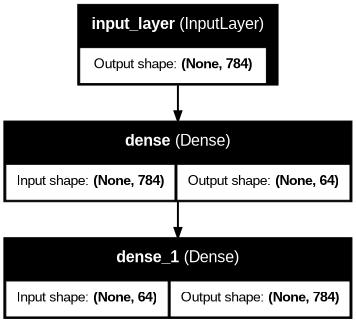

In [ ]:
from IPython.display import Image
from keras.utils import model_to_dot

Image(model_to_dot(autoencoder, show_shapes=True, dpi=70).create(format='png'))


## Entrenamiento

In [ ]:
epochs = 10
batch_size = 128

history = autoencoder.fit(x_train, x_train, batch_size=batch_size, epochs=epochs, verbose=1, validation_data=(x_test, x_test))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0445 - val_loss: 0.0227
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0175 - val_loss: 0.0129
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0109 - val_loss: 0.0087
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0078 - val_loss: 0.0066
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0062 - val_loss: 0.0055
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0053 - val_loss: 0.0049
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.0049 - val_loss: 0.0046
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0046 - val_loss: 0.0044
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0044 - val_loss: 0.0042
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0043 - val_loss: 0.0042


## Vamos a observar cómo quedó el entrenamiento reconstruyendo el modelo

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


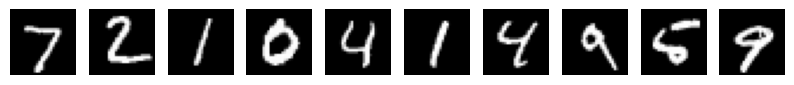

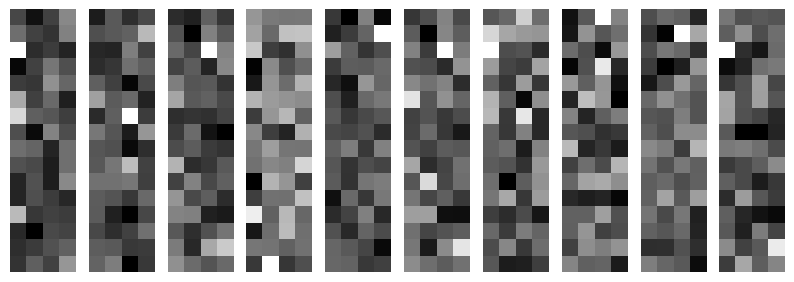

In [ ]:
encoder_model = Model(inputs=x, outputs=h)

encoder_imgs = encoder_model.predict(x_test)

#vamos a visualizar 10 imágenes codificadas
n = 10
plt.figure(figsize=(10,4))

for i in range(n):
  ax = plt.subplot(1,n, i+1)

  #h tiene tamaño 64 (reorganizamos en 4x16 para poderlo visualizar)
  plt.imshow(x_test[i].reshape(28,28), cmap='gray')
  plt.axis('off')


plt.figure(figsize=(10,4))

for i in range(n):
  ax = plt.subplot(1,n, i+1)

  #h tiene tamaño 64 (reorganizamos en 4x16 para poderlo visualizar)
  plt.imshow(encoder_imgs[i].reshape(4,16).T, cmap='gray')
  plt.axis('off')

plt.show()


## Ahora vamos a decodificar las imágenes

In [ ]:
imagenes_decodificadas = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


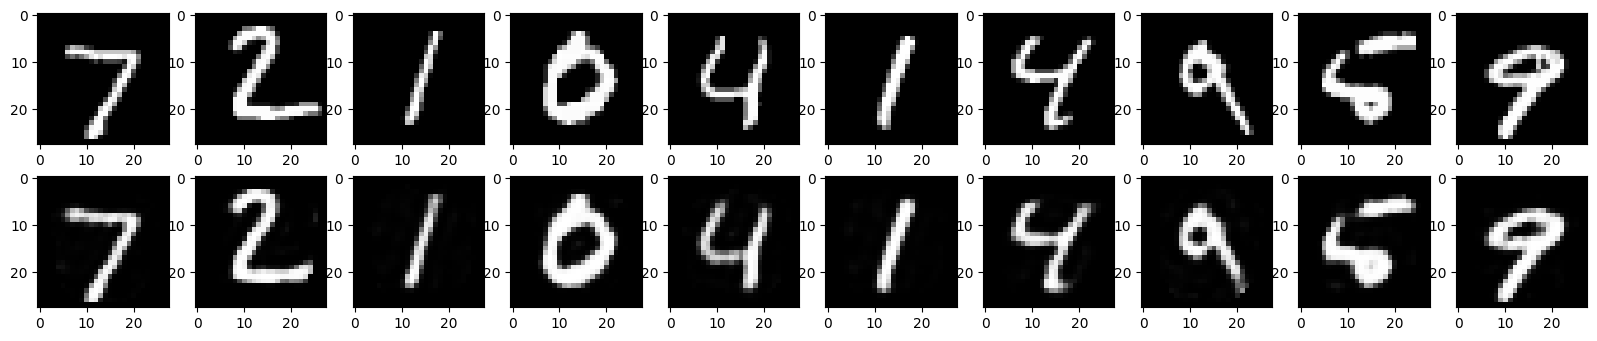

In [ ]:
n = 10
plt.figure(figsize=(20,6))
for i in range(n):
  ax = plt.subplot(3,n, i+1)
  plt.imshow(x_test[i].reshape(28,28), cmap='gray')

  ax = plt.subplot(3,n, i+n+1)
  plt.imshow(imagenes_decodificadas[i].reshape(28,28), cmap='gray')

plt.show()